# Intelligent Agents: Reflex-Based Agents for the Vacuum-cleaner World

Student Name: Nguyễn Toàn Thắng

I have used the following AI tools: ChatGPT.

I understand that my submission needs to be my own work: NTT

## Learning Outcomes

* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.
* Graduate Students: Develop strategies for handling uncertainty and imperfect information in autonomous agent systems.

## Instructions

Total Points: 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

### Using Visual Studio Code

Follow [HOWTO Setup the Used Tools] to set up your Jupyter Notebook environment.
You can use `Export` (click on `...` in the menu bar) in VS Code to save your notebook as a HTML file. Don't forget to run all blocks before, so the HTML file contains the output of the executed code.

### Using Google Colab

In Colab you need to save the notebook on GoogleDrive to work with it. For this you need to mount your google dive and change to the correct directory. The following code will try to do this if you are on Colab.

In [62]:
# change directory to Google Drive for Google Colab
# try:
#     from google.colab import drive
#     import os

#     drive.mount('/content/drive')
#     os.chdir('/content/drive/My Drive/Colab Notebooks/')
#     print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
# except ImportError:
#     pass

Once you are done with the assignment and have run all code blocks using `Runtime/Run all`, you can convert your notebook on GoogleDrive into HTML
using: [Convert a Jupyter Notebook to HTML using Colab](https://colab.research.google.com/github/mhahsler/Introduction_to_Artificial_Intelligence/blob/master/HOWTOs/colab_to_html.ipynb).

## Introduction

In this assignment you will implement a simulator environment for an automatic vacuum cleaner robot, a set of different reflex-based agent programs, and perform a comparison study for cleaning a single room. Focus on the __cleaning phase__ which starts when the robot is activated and ends when the last dirty square in the room has been cleaned. Someone else will take care of the agent program needed to navigate back to the charging station after the room is clean.

## PEAS description of the cleaning phase

The PEAS description is used in the design phase for an intelligent agent. Make sure your implementations follow this description:

* __Performance Measure:__ Each action costs 1 energy unit. The performance is measured as the sum of the energy units used to clean the whole room.

* __Environment:__ A room with $n \times n$ squares where $n = 5$. Dirt is randomly placed on each square with probability $p = 0.2$. For simplicity, you can assume that the agent knows the size and the layout of the room (i.e., it knows $n$). To start, the agent is placed on a random square.

* __Actuators:__ The agent can clean the current square (action `suck`) or move to an adjacent square by going `north`, `east`, `south`, or `west`.

* __Sensors:__ Four bumper sensors, one for north, east, south, and west; a dirt sensor reporting dirt in the current square.  


## The agent program for a simple randomized agent

To show the structure of an agent program, I implement here a simple randomized agent that chooses its actions randomly.

The agent program is implemented as a function that gets sensor information (the current percepts) as the arguments. 
We will use the parameters:

* `bumpers`: A dictionary with boolean entries for the for bumper sensors `north`, `east`, `west`, `south`. E.g., if the agent is on the north-west corner, `bumpers` will be `{"north" : True, "east" : False, "south" : False, "west" : True}`.
* `dirty`: A boolean representing the dirt sensor.

The agent returns the chosen action as a string.

Here is an example implementation for the agent program of a simple randomized agent:  

In [63]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "numpy>=1.26,<3"

In [64]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [65]:
# define percepts (current location is NW corner and it is dirty)
bumpers = {"north" : True, "east" : False, "south" : False, "west" : True}
dirty = True

# call agent program function with percepts and it returns an action
simple_randomized_agent(bumpers, dirty)

np.str_('north')

__Note:__ This is not a rational intelligent agent. It ignores its sensors and may bump into a wall repeatedly or not clean a dirty square. You will be asked to implement rational agents below.

## Simple environment example

I show here how to implement a simple simulation environment that supplies the agent program with its percepts and evaluates the agent's actions.
As an example, I implement a room of infinite in size (bumpers are always `False`) where every square is always dirty, even if the agent cleans it. The environment function returns a different performance measure than the one specified in the PEAS description! Since the room is infinite and all squares are constantly dirty, the agent can never clean the whole room. Your implementation needs to implement the **correct performance measure.** The energy budget of the agent is specified as `max_steps`. 

In [66]:
def simple_environment(agent_function, max_steps, verbose = True):
    num_cleaned = 0
    
    for i in range(max_steps):
        dirty = True
        bumpers = {"north" : False, "south" : False, "west" : False, "east" : False}

        action = agent_function(bumpers, dirty)
        if (verbose): print("step", i , "- action:", action) 
        
        if (action == "suck"): 
            num_cleaned = num_cleaned + 1
        
    return num_cleaned
        


Do one simulation run with a simple randomized agent that has enough energy for 20 steps.

In [67]:
simple_environment(simple_randomized_agent, max_steps = 20)

step 0 - action: suck
step 1 - action: north
step 2 - action: east
step 3 - action: suck
step 4 - action: east
step 5 - action: suck
step 6 - action: south
step 7 - action: east
step 8 - action: west
step 9 - action: south
step 10 - action: east
step 11 - action: east
step 12 - action: suck
step 13 - action: west
step 14 - action: south
step 15 - action: west
step 16 - action: north
step 17 - action: east
step 18 - action: west
step 19 - action: west


4

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Implement a simulation environment [20 Points]

The simple environment above is not very realistic. Your environment simulator needs to follow the PEAS description from above. It needs to:

* Initialize the environment by storing the state of each square (clean/dirty) and making some dirty. ([Help with random numbers and arrays in Python])
* Keep track of the agent's position.
* Call the agent function repeatedly and provide the agent function with the sensor inputs.  
* React to the agent's actions. E.g, by removing dirt from a square or moving the agent around unless there is a wall in the way.
* Keep track of the performance measure. That is, track the agent's actions until all dirty squares are clean and count the number of actions it takes the agent to complete the task.

The easiest implementation for the environment is to hold an 2-dimensional array to represent if squares are clean or dirty and to call the agent function in a loop until all squares are clean or a predefined number of steps have been reached (i.e., the robot runs out of energy).

The simulation environment should be a function like the `simple_environment()` and needs to work with the simple randomized agent program from above. **Use the same environment for all your agent implementations in the tasks below.**

*Note on debugging:* Debugging can be difficult. Here are a few options:

* Make sure your environment prints enough information when you use `verbose = True`. 
* VSCode also provides a very good interactive Python debugger for notebooks. Read the [HOWTO on debugging](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/debugging_in_notebooks.ipynb) for more details. 
* Another very useful debugging help is to implement a function that the environment can use to displays the room with dirt and the current position of the robot at every step. You can use simple characters for dirt and the robot location.  

In [68]:
# 1. Initialize environment
room_size = 5

# 0 = clean, 1 = dirty
room = np.random.randint(0, 2, size=(room_size, room_size))


# 2. Initialize agent's position
agent_position = [
    np.random.randint(0, room_size),
    np.random.randint(0, room_size)
]


# 3. Display room with agent
def state_room(room, agent_position):
    display_room = room.copy()

    row, col = agent_position
    display_room[row, col] = -1

    return display_room


print("Original room:")
print(room)

print("Total trash:", np.sum(room))
print("Agent position:", agent_position)

print("Room with agent:")
print(state_room(room, agent_position))


# 4. Environment
def environment(
    agent,
    agent_position,
    room,
    room_size=5,
    max_steps=20,
    verbose=False
):
    count_step = 0

    while count_step < max_steps:

        # Stop if the room is completely clean
        if np.sum(room) == 0:
            if verbose:
                print("Completely clean")
            break

        row, col = agent_position

        # ----- Sensors -----

        # Dirt sensor
        dirty = room[row, col] == 1

        # Bumper sensors
        bumpers = {
            "north": row == 0,
            "east": col == room_size - 1,
            "south": row == room_size - 1,
            "west": col == 0
        }

        # ----- Agent chooses action -----
        action = agent(bumpers, dirty)

        count_step += 1

        if verbose:
            print("\nStep:", count_step)
            print("Position:", agent_position)
            print("Dirty:", dirty)
            print("Bumpers:", bumpers)
            print("Action:", action)

        # ----- Environment reacts to action -----

        if action == "suck":
            room[row, col] = 0

        elif action == "north":
            if not bumpers["north"]:
                agent_position[0] -= 1

        elif action == "south":
            if not bumpers["south"]:
                agent_position[0] += 1

        elif action == "east":
            if not bumpers["east"]:
                agent_position[1] += 1

        elif action == "west":
            if not bumpers["west"]:
                agent_position[1] -= 1

        if verbose:
            print("Trash remaining:", np.sum(room))
            print(state_room(room, agent_position))

    success = np.sum(room) == 0

    if verbose:
        print("\n--- Simulation finished ---")
        print("Steps:", count_step)
        print("Success:", success)
        print("Trash remaining:", np.sum(room))
        print("Final position:", agent_position)

    return count_step, success

Original room:
[[0 0 0 1 1]
 [0 1 0 1 1]
 [1 1 0 1 0]
 [1 0 1 0 0]
 [0 0 1 0 0]]
Total trash: 11
Agent position: [4, 0]
Room with agent:
[[ 0  0  0  1  1]
 [ 0  1  0  1  1]
 [ 1  1  0  1  0]
 [ 1  0  1  0  0]
 [-1  0  1  0  0]]


Show that your environment works with the simple randomized agent from above.

In [69]:
# Your code and description goes here
simple_randomized_room = room.copy()
simple_randomized_agent_position = agent_position.copy()
environment(simple_randomized_agent, simple_randomized_agent_position, simple_randomized_room)

(20, np.False_)

## Task 2:  Implement a simple reflex agent [10 Points] 

The simple reflex agent randomly walks around but reacts to the bumper sensor by not bumping into the wall and to dirt with sucking. Implement the agent program as a function.

_Note:_ Agents cannot directly use variable in the environment. They only gets the percepts as the arguments to the agent function. Use the function signature for the `simple_randomized_agent` function above.

In [70]:
# Your code and description goes here
def simple_reflex_agent(bumpers, dirty):
    if dirty:
        return "suck"

    valid_actions = []

    if not bumpers["north"]:
        valid_actions.append("north")

    if not bumpers["east"]:
        valid_actions.append("east")

    if not bumpers["south"]:
        valid_actions.append("south")

    if not bumpers["west"]:
        valid_actions.append("west")

    return np.random.choice(valid_actions)

Show how the agent works with your environment.

In [71]:
# Your code and description goes here
simple_reflex_room = room.copy()
simple_reflex_agent_position = agent_position.copy()
environment(simple_reflex_agent, simple_reflex_agent_position ,simple_reflex_room)

(20, np.False_)

## Task 3: Implement a model-based reflex agent [20 Points]

Model-based agents use a state to keep track of what they have done and perceived so far. Your agent needs to find out where it is located and then keep track of its current location. You also need a set of rules based on the state and the percepts to make sure that the agent will clean the whole room. For example, the agent can move to a corner to determine its location and then it can navigate through the whole room and clean dirty squares.

Describe how you define the __agent state__ and how your agent works before implementing it. ([Help with implementing state information in Python])

In [72]:
# The agent maintains an internal state containing whether it has localized itself, its estimated current position, 
# and its current horizontal traversal direction. Initially, the agent moves north until reaching the north wall, 
# then west until reaching the west wall. It then knows it is located at the north-west corner. 
# From there, it traverses the room using a serpentine pattern and sucks whenever the dirt sensor is active


In [73]:
# Internal state of model-based agent
model_state = {
    "phase": "find_north",   # find_north -> find_west -> clean
    "direction": "east",
    "position": None
}


def model_based_reflex_agent(bumpers, dirty):
    global model_state

    # Always clean current square first
    if dirty:
        return "suck"

    # Phase 1: move to the north wall
    if model_state["phase"] == "find_north":

        if not bumpers["north"]:
            return "north"

        # Reached north wall
        model_state["phase"] = "find_west"


    # Phase 2: move to the west wall
    if model_state["phase"] == "find_west":

        if not bumpers["west"]:
            return "west"

        # Now we know we are at north-west corner
        model_state["phase"] = "clean"
        model_state["position"] = [0, 0]
        model_state["direction"] = "east"


    # Phase 3: clean room using zig-zag movement
    if model_state["phase"] == "clean":

        # ---- Moving EAST ----
        if model_state["direction"] == "east":

            if not bumpers["east"]:
                model_state["position"][1] += 1
                return "east"

            # East wall reached -> move down
            if not bumpers["south"]:
                model_state["position"][0] += 1
                model_state["direction"] = "west"
                return "south"


        # ---- Moving WEST ----
        elif model_state["direction"] == "west":

            if not bumpers["west"]:
                model_state["position"][1] -= 1
                return "west"

            # West wall reached -> move down
            if not bumpers["south"]:
                model_state["position"][0] += 1
                model_state["direction"] = "east"
                return "south"

    # Normally environment should stop before reaching here
    return "suck"

Show how the agent works with your environment.

In [74]:
model_based_room = room.copy()
model_based_agent_position = agent_position.copy()

environment(
    model_based_reflex_agent,
    model_based_agent_position,
    model_based_room
)

(20, np.False_)

## Task 4: Simulation study [30 Points]

Compare the performance (the performance measure is defined in the PEAS description above) of the agents using  environments of different size. Do at least $5 \times 5$, $10 \times 10$ and
$100 \times 100$. Use 100 random runs for each. Present the results using tables and graphs. Discuss the differences between the agents. 
([Help with charts and tables in Python](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/charts_and_tables.ipynb))

In [75]:
def run_simulation(agent, room, agent_position, max_steps):
    room_copy = room.copy()
    position_copy = agent_position.copy()

    return environment(
        agent,
        position_copy,
        room_copy,
        room_size=room.shape[0],
        max_steps=max_steps,
    )
    
def reset_model_state():
    global model_state

    model_state = {
        "phase": "find_north",
        "direction": "east",
        "position": None
    }

Fill out the following table with the average performance measure for 100 random runs (you may also create this table with code):

| Size     | Randomized Agent | Simple Reflex Agent | Model-based Reflex Agent |
|----------|------------------|---------------------|--------------------------|
| 5x5     | | | |
| 10x10   | | | |
| 100x100 | | | |

Add charts to compare the performance of the different agents.

In [76]:
def evaluate_agents(room_size, runs=100):

    randomized_results = []
    simple_reflex_results = []
    model_based_results = []

    for _ in range(runs):

        # Same initial environment for all agents
        room = np.random.randint(
            0, 2,
            size=(room_size, room_size)
        )

        agent_position = [
            np.random.randint(0, room_size),
            np.random.randint(0, room_size)
        ]

        # Randomized agent
        steps = run_simulation(
            simple_randomized_agent,
            room,
            agent_position,
            max_steps=room_size * room_size * 20
        )
        randomized_results.append(steps)

        # Simple reflex agent
        steps = run_simulation(
            simple_reflex_agent,
            room,
            agent_position,
            max_steps=room_size * room_size * 20
        )
        simple_reflex_results.append(steps)

        # Model-based agent
        reset_model_state()

        steps = run_simulation(
            model_based_reflex_agent,
            room,
            agent_position,
            max_steps=room_size * room_size * 20
        )
        model_based_results.append(steps)

    return {
        "Randomized": np.mean(randomized_results),
        "Simple Reflex": np.mean(simple_reflex_results),
        "Model-Based": np.mean(model_based_results)
    }
    

In [77]:
sizes = [5, 10, 100]

results = {}

for size in sizes:
    results[size] = evaluate_agents(size, runs=10)
    
import pandas as pd

df = pd.DataFrame(results).T

df.index = ["5x5", "10x10", "100x100"]
df.index.name = "Room Size"

df

,Randomized,Simple Reflex,Model-Based
Room Size,,,
5x5,221.2,51.95,19.70
10x10,1000.0,630.90,79.50
100x100,100000.0,100000.00,7557.85


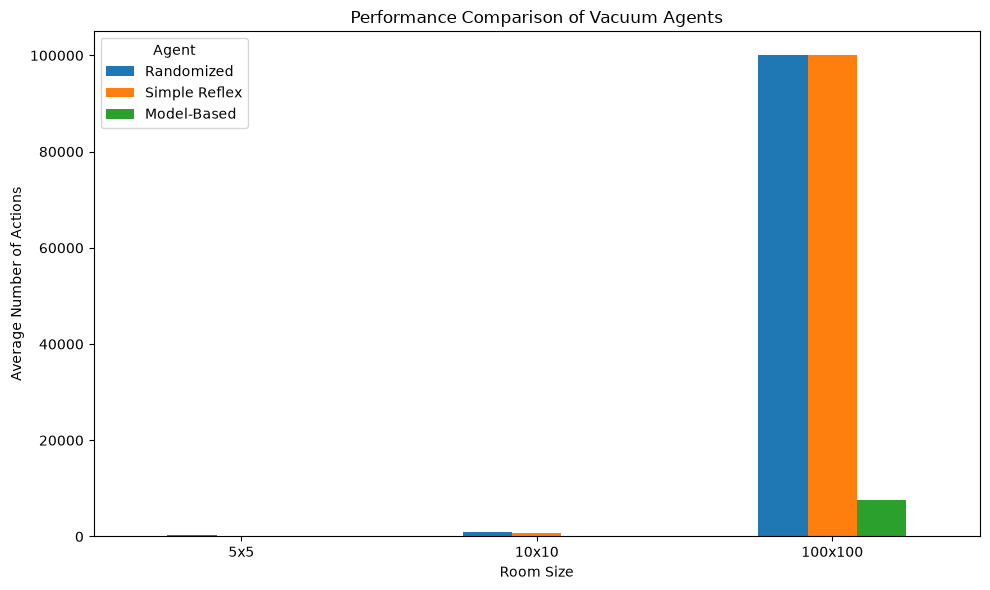

In [78]:
import matplotlib.pyplot as plt

df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of Vacuum Agents")
plt.xlabel("Room Size")
plt.ylabel("Average Number of Actions")
plt.xticks(rotation=0)
plt.legend(title="Agent")
plt.tight_layout()

plt.show()

## Task 5: Robustness of the agent implementations [10 Points] 

Describe how **your agent implementations** will perform 

* if it is put into a rectangular room with unknown size, 
* if the cleaning area can have an irregular shape (e.g., a hallway connecting two rooms), or 
* if the room contains obstacles (i.e., squares that it cannot pass through and trigger the bumper sensors).
* if the dirt sensor is not perfect and gives 10% of the time a wrong reading (clean when it is dirty or dirty when it is clean).
* if the bumper sensor is not perfect and 10% of the time does not report a wall when there is one.

### Task 5: Robustness of the Agent Implementations

The robustness of the three implemented agents is analyzed under different environment conditions and imperfect sensor readings.

| Scenario | Simple Randomized Agent | Simple Reflex Agent | Model-Based Reflex Agent |
|---|---|---|---|
| **Rectangular room with unknown size** | The agent can still move and clean randomly, but it may require many actions. | The agent can operate normally because it uses bumper sensors to avoid walls and the dirt sensor to clean. However, its movement is still random. | The agent can handle this case well. It can move north and west until reaching the top-left corner, then use a zigzag strategy without knowing the room size in advance. |
| **Irregular-shaped cleaning area** | The agent may eventually explore different areas randomly, but there is no guarantee that all areas will be visited efficiently. | The agent can avoid walls, but random movement does not guarantee complete coverage. | The current zigzag strategy assumes a rectangular room, so irregular shapes may cause some areas to be skipped. |
| **Obstacles inside the room** | The agent may repeatedly choose actions toward obstacles because it ignores bumper information. | The agent can detect obstacles using bumper sensors and avoid moving into them. | Internal obstacles may be mistaken for room boundaries. This can interrupt the zigzag pattern and may cause some areas to remain unexplored. |
| **Dirt sensor gives 10% wrong readings** | The effect is limited because the randomized agent does not use the dirt sensor when selecting actions. | A false clean reading may cause the agent to leave a dirty square, while a false dirty reading may cause an unnecessary suck action. | A false clean reading may cause the agent to skip dirt during its systematic traversal. A false dirty reading causes an unnecessary suck action. |
| **Bumper sensor misses a wall 10% of the time** | The randomized agent already ignores bumper information, so it may frequently attempt invalid movements. | The agent may incorrectly choose a direction that contains a wall, causing a wasted action. | This can have a larger effect because the agent uses bumper information for localization and navigation. Incorrect readings may cause its internal position or traversal strategy to become inconsistent with the real environment. |

#### Discussion

The **Simple Randomized Agent** is the least dependent on sensor accuracy because it chooses actions randomly. However, this also makes it inefficient and unable to systematically clean the environment.

The **Simple Reflex Agent** performs better because it reacts directly to the current bumper and dirt sensors. It can avoid detected walls and clean dirty squares, but it does not maintain memory of previously visited locations.

The **Model-Based Reflex Agent** is the most systematic in a regular rectangular environment. It first localizes itself by moving toward the top-left corner and then follows a zigzag cleaning pattern. However, because its strategy depends on its internal state and sensor readings, obstacles, irregular room shapes, or incorrect bumper readings may cause its internal model to differ from the actual environment.

Overall, the current model-based strategy is effective for the assumed rectangular room with reliable sensors, but additional mechanisms would be required to make it robust to irregular environments, obstacles, and sensor errors.

## Advanced task: Imperfect Dirt Sensor

* __Students__ need to complete this task [10 points]

1. Change your simulation environment to run experiments for the following problem: The dirt sensor has a 10% chance of giving the wrong reading. Perform experiments to observe how this changes the performance of the three implementations. Your model-based reflex agent is likely not able to clean the whole room, so you need to measure performance differently as a tradeoff between energy cost and number of uncleaned squares. 

2. Design an implement a solution for your model-based agent that will clean better. Show the improvement with experiments.

In [79]:
def run_simulation(
    agent,
    agent_position,
    room,
    room_size=5,
    max_steps=20,
    verbose=False,
    dirt_sensor_error=0.0
):
    count_step = 0

    while count_step < max_steps:

        if np.sum(room) == 0:
            break

        row, col = agent_position

        # ----- Dirt sensor -----
        real_dirty = room[row, col] == 1

        if np.random.random() < dirt_sensor_error:
            dirty = not real_dirty
        else:
            dirty = real_dirty

        # ----- Bumper sensors -----
        bumpers = {
            "north": row == 0,
            "east": col == room_size - 1,
            "south": row == room_size - 1,
            "west": col == 0
        }

        action = agent(bumpers, dirty)
        count_step += 1

        if action == "suck":
            room[row, col] = 0

        elif action == "north" and not bumpers["north"]:
            agent_position[0] -= 1

        elif action == "south" and not bumpers["south"]:
            agent_position[0] += 1

        elif action == "east" and not bumpers["east"]:
            agent_position[1] += 1

        elif action == "west" and not bumpers["west"]:
            agent_position[1] -= 1

    remaining_dirt = np.sum(room)
    success = remaining_dirt == 0

    return count_step, success, remaining_dirt

In [82]:
def evaluate_agents(room_size, runs=100, dirt_sensor_error=0.0):

    randomized_steps = []
    randomized_success = []
    randomized_dirt = []

    simple_reflex_steps = []
    simple_reflex_success = []
    simple_reflex_dirt = []

    model_based_steps = []
    model_based_success = []
    model_based_dirt = []

    for _ in range(runs):

        # Same initial environment for all agents
        room = np.random.randint(
            0, 2,
            size=(room_size, room_size)
        )

        agent_position = [
            np.random.randint(0, room_size),
            np.random.randint(0, room_size)
        ]

        max_steps = room_size * room_size * 20


        # =========================
        # Randomized Agent
        # =========================
        steps, success, remaining_dirt = run_simulation(
            simple_randomized_agent,
            room=room.copy(),
            agent_position=agent_position.copy(),
            room_size=room_size,
            max_steps=max_steps,
            dirt_sensor_error=dirt_sensor_error
        )

        randomized_steps.append(steps)
        randomized_success.append(success)
        randomized_dirt.append(remaining_dirt)


        # =========================
        # Simple Reflex Agent
        # =========================
        steps, success, remaining_dirt = run_simulation(
            simple_reflex_agent,
            room=room.copy(),
            agent_position=agent_position.copy(),
            room_size=room_size,
            max_steps=max_steps,
            dirt_sensor_error=dirt_sensor_error
        )

        simple_reflex_steps.append(steps)
        simple_reflex_success.append(success)
        simple_reflex_dirt.append(remaining_dirt)


        # =========================
        # Model-Based Agent
        # =========================
        reset_model_state()

        steps, success, remaining_dirt = run_simulation(
            model_based_reflex_agent,
            room=room.copy(),
            agent_position=agent_position.copy(),
            room_size=room_size,
            max_steps=max_steps,
            dirt_sensor_error=dirt_sensor_error
        )

        model_based_steps.append(steps)
        model_based_success.append(success)
        model_based_dirt.append(remaining_dirt)


    return {
        "Randomized Steps": np.mean(randomized_steps),
        "Randomized Success Rate": np.mean(randomized_success) * 100,
        "Randomized Remaining Dirt": np.mean(randomized_dirt),

        "Simple Reflex Steps": np.mean(simple_reflex_steps),
        "Simple Reflex Success Rate": np.mean(simple_reflex_success) * 100,
        "Simple Reflex Remaining Dirt": np.mean(simple_reflex_dirt),

        "Model-Based Steps": np.mean(model_based_steps),
        "Model-Based Success Rate": np.mean(model_based_success) * 100,
        "Model-Based Remaining Dirt": np.mean(model_based_dirt)
    }

In [83]:
results_imperfect = {}

for size in [5, 10, 100]:
    results_imperfect[size] = evaluate_agents(
        size,
        runs=100,
        dirt_sensor_error=0.1
    )

## More Advanced Implementation (not for credit)

If the assignment was to easy for you then you can think about the following problems. These problems are challenging and not part of this assignment. We will learn implementation strategies and algorithms useful for these tasks during the rest of the semester.

* __Obstacles:__ Change your simulation environment to run experiments for the following problem: Add random obstacle squares that also trigger the bumper sensor. The agent does not know where the obstacles are. Perform experiments to observe how this changes the performance of the three implementations. Describe what would need to be done to perform better with obstacles. Add code if you can. 

* __Agent for and environment with obstacles:__ Implement an agent for an environment where the agent does not know how large the environment is (we assume it is rectangular), where it starts or where the obstacles are. An option would be to always move to the closest unchecked/uncleaned square (note that this is actually depth-first search).

* __Utility-based agent:__ Change the environment for a $5 \times 5$ room, so each square has a fixed probability of getting dirty again. For the implementation, we give the environment a 2-dimensional array of probabilities. The utility of a state is defined as the number of currently clean squares in the room. Implement a utility-based agent that maximizes the expected utility over one full charge which lasts for 100000 time steps. To do this, the agent needs to learn the probabilities with which different squares get dirty again. This is very tricky!

### Ideas for More Advanced Implementation

#### 1. Handling Obstacles
Random obstacle cells can be added to the environment. These cells cannot be entered and will trigger the corresponding bumper sensor.  
The current simple reflex agent can avoid an obstacle when it detects one, but the current model-based zigzag strategy may incorrectly treat an obstacle as a room boundary.

A better solution would be for the model-based agent to:
- store detected obstacle locations in its internal state,
- distinguish between room boundaries and internal obstacles,
- choose another route when the normal zigzag path is blocked,
- keep track of unvisited squares so that blocked areas can be explored later.

#### 2. Unknown Environment with Obstacles
If the room size and obstacle locations are unknown, the agent can gradually build an internal map while moving.

The agent can:
- remember visited squares,
- remember detected obstacles,
- keep a list of unexplored neighboring squares,
- move toward an unexplored square whenever possible,
- backtrack when no unexplored neighbor is available.

This idea is similar to a depth-first search strategy and can help the agent eventually explore most reachable parts of the environment.

#### 3. Utility-Based Agent
For a room where cleaned squares can become dirty again, the agent should not only focus on cleaning every square once.

Instead, the agent can estimate how frequently each square becomes dirty and assign higher priority to squares with a higher probability of becoming dirty again.

The agent could maintain statistics for each square, such as:
- number of visits,
- number of times dirt was detected,
- estimated probability of becoming dirty again.

The agent would then choose actions that maximize the expected number of clean squares while also considering the energy cost of movement.